# 워크플로우와 에이전트 경계

이 절은 LLM 앱의 구조를 두 가지로 가르는 기준을 세웁니다.
기준은 다음 단계를 누가 골랐는가 하나입니다.
코드가 고르면 워크플로우이고, 모델이 고르면 에이전트 쪽입니다.

**이 노트북에서 할 일**

1. 단계 하나를 딕셔너리 한 줄로 적는 실행 기록의 모양을 봅니다.
2. 이 절에서 만든 사례 넷의 기록을 적고 한 줄씩 읽습니다.
3. 기록에서 모델이 고른 단계를 세어 구조를 가르는 함수를 만듭니다.
4. 도구 단계를 늘리거나 고른 쪽 한 줄만 바꿔 구조가 바뀌는지 봅니다.

**준비물** — 이 절은 모델을 부르지 않습니다.
기록을 읽고 가르는 법을 익히는 절이라 이 절에서 손으로 만든 기록을 씁니다.
그래서 OpenAI API 키가 필요 없고 모델 요청은 0번이며 드는 비용도 없습니다.
읽는 자료 파일도 새로 쓰는 파일도 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 1초 안에 끝났습니다.

**기준 버전** — 파이썬에 들어 있는 기능만 써서 설치할 패키지가 없습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~7절을 읽습니다.
실행 기록의 모양을 보고 사례 넷을 가르는 자리입니다.
8절 라우팅 사례, 9·10절 값 바꿔 보기, 11절 모아 세기는 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch17-agent-overview`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

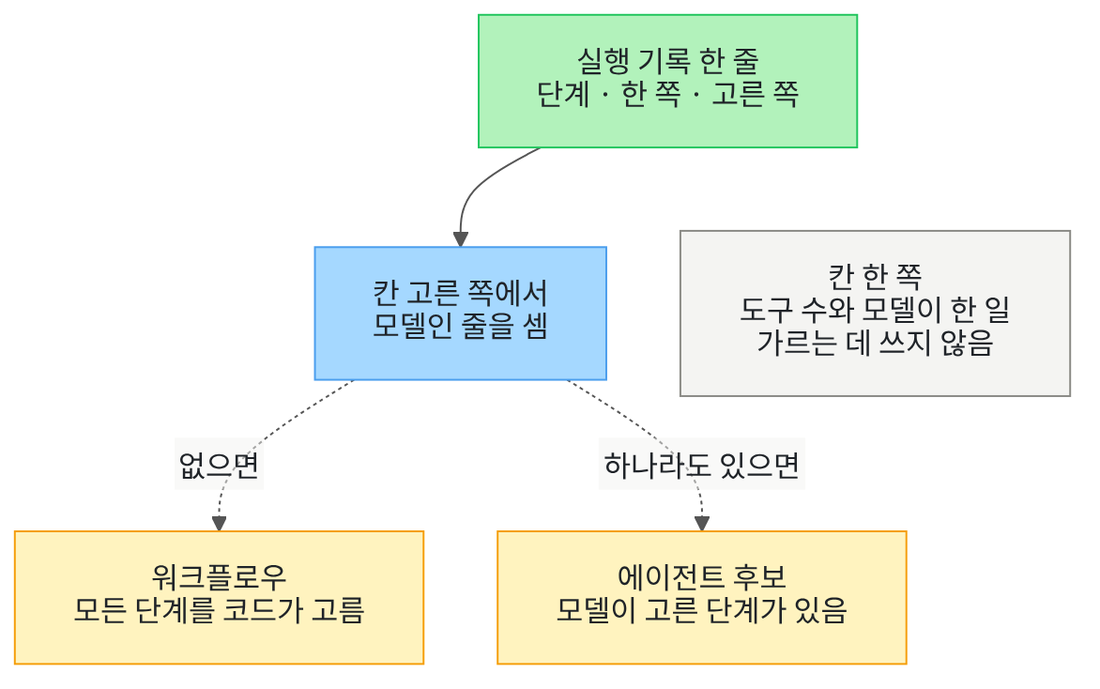

위에서 아래로 읽습니다. 초록 기록 한 줄에서 파란 상자가 칸 「고른 쪽」이 모델인 줄을 셉니다.
모델인 줄이 없으면 왼쪽 점선, 하나라도 있으면 오른쪽 점선을 따라 노란 결과가 나옵니다.
파란 상자 오른쪽의 회색 상자는 가르는 데 쓰지 않는 칸 「한 쪽」입니다.

## 1. 준비

이 절은 파이썬에 들어 있는 기능만 씁니다.
설치할 패키지가 없으므로 첫 셀은 실행하는 파이썬의 판만 확인합니다.
첫 줄 `import sys`는 파이썬 실행 정보를 담은 기능 묶음을 불러옵니다.

In [1]:
# 이 노트북을 실행하는 파이썬 판을 확인합니다(설치할 패키지는 없습니다)
import sys

python_version = sys.version.split()[0]
print("파이썬 판:", python_version)

파이썬 판: 3.12.13


**결과 읽기** — 교재 출력에서는 출력 줄 `파이썬 판: 3.12.13`이 보입니다.
값 `sys.version`은 판 번호 뒤에 만든 날짜 같은 글이 붙어 있어 빈칸으로 나눠 첫 값만 씁니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

## 2. 실행 기록 한 줄의 모양

Ch 15 05절에서는 실행 추적(trace)이라는 기록을 만들었습니다.
요청 한 번이 지나간 단계와 걸린 시간, 사용량을 한데 적은 기록입니다.
이 절의 기록은 걸린 시간과 사용량 없이 단계만 차례로 적습니다.
단계 하나는 한국어 키를 쓴 딕셔너리 한 줄입니다.

칸은 셋입니다.
칸 「단계」는 그 단계에서 한 일의 이름입니다.
칸 「한 쪽」은 그 일을 실제로 한 쪽이고 `코드`·`도구`·`모델` 가운데 하나를 적습니다.
칸 「고른 쪽」은 이 단계를 다음에 하기로 정한 쪽이고 `코드`·`모델` 가운데 하나를 적습니다.

도구(tool)는 모델 밖에서 정해진 일 하나를 하는 함수나 서비스입니다.
주문 조회, 문서 검색, 파일 읽기가 예입니다.

In [2]:
# 실행 기록 한 줄의 모양입니다: 단계 이름, 그 일을 한 쪽, 이 단계를 고른 쪽
first_step = {"단계": "주문 조회", "한 쪽": "도구", "고른 쪽": "코드"}
print("단계:", first_step["단계"])
print("한 쪽:", first_step["한 쪽"])
print("고른 쪽:", first_step["고른 쪽"])

단계: 주문 조회
한 쪽: 도구
고른 쪽: 코드


**결과 읽기** — 출력 줄 `단계: 주문 조회`·`한 쪽: 도구`·`고른 쪽: 코드`가 칸 셋의 값입니다.
주문 조회라는 일은 도구가 했고, 이 단계를 하기로 정한 것은 코드라는 뜻입니다.
칸 「한 쪽」과 칸 「고른 쪽」은 서로 다른 칸이라 값이 달라도 됩니다.

## 3. 이 절에서 만든 사례 넷

아래 네 기록은 이 절에서 손으로 만든 사례입니다.
실제 제품이나 서비스를 실행해서 얻은 기록이 아닙니다.
구조를 가르는 기준을 연습하려고 단계 이름과 칸 값을 정해 적었습니다.

첫 사례는 정해진 환불 절차입니다.
주문을 조회하고 환불 규정을 확인한 뒤 환불 요청을 등록합니다.
마지막에 모델이 고객에게 보낼 안내 문장을 씁니다.
네 단계의 차례가 코드에 미리 적혀 있어 칸 「고른 쪽」은 모두 `코드`입니다.

In [3]:
# 사례 1 · 정해진 환불 절차: 코드가 적어 둔 차례대로 네 단계를 지납니다
refund_steps = [
    {"단계": "주문 조회", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "환불 규정 확인", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "환불 요청 등록", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "안내 문장 쓰기", "한 쪽": "모델", "고른 쪽": "코드"},
]
print("환불 절차 기록 줄 수:", len(refund_steps))

환불 절차 기록 줄 수: 4


**결과 읽기** — 출력 줄 `환불 절차 기록 줄 수: 4`로 단계가 넷입니다.
도구가 세 단계를 했고 모델이 한 단계를 했습니다.
그래도 네 줄 모두 칸 「고른 쪽」은 `코드`입니다.

둘째 사례는 문서를 요약한 뒤 형식을 검사하는 절차입니다.
모델이 요약을 쓰지만, 요약을 쓸 때와 그다음 검사할 때는 코드가 정합니다.

In [4]:
# 사례 2 · 문서 요약 뒤 형식 검사: 모델이 요약을 쓰지만 차례는 코드가 정합니다
summary_steps = [
    {"단계": "문서 읽기", "한 쪽": "코드", "고른 쪽": "코드"},
    {"단계": "요약 쓰기", "한 쪽": "모델", "고른 쪽": "코드"},
    {"단계": "형식 검사", "한 쪽": "코드", "고른 쪽": "코드"},
]
print("요약 절차 기록 줄 수:", len(summary_steps))

요약 절차 기록 줄 수: 3


**결과 읽기** — 출력 줄 `요약 절차 기록 줄 수: 3`으로 단계가 셋입니다.
가운데 줄에서만 모델이 일을 했고, 세 줄 모두 칸 「고른 쪽」은 `코드`입니다.

셋째 사례는 여러 파일에 걸친 결함을 고치는 일입니다.
어느 파일을 먼저 볼지, 고친 뒤 무엇을 할지는 해 보기 전에 알 수 없습니다.
그래서 모델이 앞 단계의 결과를 보고 다음 단계를 고른다고 적었습니다.

In [5]:
# 사례 3 · 여러 파일의 결함 고치기: 모델이 앞 결과를 보고 다음 단계를 고릅니다
bugfix_steps = [
    {"단계": "파일 목록 보기", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "파일 읽기", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "고친 코드 쓰기", "한 쪽": "모델", "고른 쪽": "모델"},
    {"단계": "시험 실행", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "다른 파일 읽기", "한 쪽": "도구", "고른 쪽": "모델"},
]
print("결함 고치기 기록 줄 수:", len(bugfix_steps))

결함 고치기 기록 줄 수: 5


**결과 읽기** — 출력 줄 `결함 고치기 기록 줄 수: 5`로 단계가 다섯입니다.
다섯 줄 모두 칸 「고른 쪽」이 `모델`입니다.
시험 실행 뒤에 다른 파일을 읽은 것도 모델이 고른 단계입니다.

넷째 사례는 처음 보는 장애의 원인을 찾는 일입니다.
첫 단계인 오류 기록 검색만 코드가 정해 두었습니다.
그 뒤는 모델이 검색 결과를 보고 다음 단계를 고른다고 적었습니다.

In [6]:
# 사례 4 · 낯선 장애 원인 조사: 첫 단계만 코드가 정하고 그 뒤는 모델이 고릅니다
incident_steps = [
    {"단계": "오류 기록 검색", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "설정 파일 읽기", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "오류 기록 검색", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "원인 보고 쓰기", "한 쪽": "모델", "고른 쪽": "모델"},
]
print("장애 조사 기록 줄 수:", len(incident_steps))

장애 조사 기록 줄 수: 4


**결과 읽기** — 출력 줄 `장애 조사 기록 줄 수: 4`로 단계가 넷입니다.
오류 기록 검색이 두 번 나옵니다.
두 번째 검색은 모델이 설정 파일을 읽은 뒤 다시 고른 단계입니다.

다음 셀은 네 사례를 이름과 기록으로 묶어 목록 하나에 담습니다.
사례 하나는 칸 「이름」과 칸 「기록」을 가진 딕셔너리입니다.

In [7]:
# 사례 넷을 이름과 기록으로 묶어 목록 하나에 담습니다
cases = [
    {"이름": "정해진 환불 절차", "기록": refund_steps},
    {"이름": "문서 요약 뒤 형식 검사", "기록": summary_steps},
    {"이름": "여러 파일의 결함 고치기", "기록": bugfix_steps},
    {"이름": "낯선 장애 원인 조사", "기록": incident_steps},
]
print("사례 수:", len(cases))

사례 수: 4


**결과 읽기** — 출력 줄 `사례 수: 4`로 네 사례가 목록에 들어갔습니다.
칸 「기록」에는 앞에서 만든 기록 목록이 그대로 들어 있습니다.

## 4. 기록을 한 줄씩 읽기

다음 셀은 기록 하나를 받아 줄마다 번호와 칸 셋을 출력하는 함수입니다.
번호 `i`로 목록을 차례대로 돕니다.
여러 줄로 나오므로 라벨 줄을 먼저 출력합니다.

In [8]:
# 기록 하나를 줄마다 번호·단계·한 쪽·고른 쪽 차례로 출력합니다
def print_steps(steps):
    print("번호 | 단계 | 한 쪽 | 고른 쪽")
    for i in range(len(steps)):
        step = steps[i]
        print(i, "|", step["단계"], "|", step["한 쪽"], "|", step["고른 쪽"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_steps`는 라벨 줄 하나를 먼저 출력하고, 기록의 줄마다 한 줄씩 출력합니다.
번호는 0부터 셉니다.

다음 셀은 사례 1 기록을 읽습니다.

In [9]:
# 사례 1 기록을 한 줄씩 읽습니다
print_steps(refund_steps)

번호 | 단계 | 한 쪽 | 고른 쪽
0 | 주문 조회 | 도구 | 코드
1 | 환불 규정 확인 | 도구 | 코드
2 | 환불 요청 등록 | 도구 | 코드
3 | 안내 문장 쓰기 | 모델 | 코드


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽` 아래 네 줄이 환불 절차입니다.
출력 줄 `0 | 주문 조회 | 도구 | 코드`부터 `3 | 안내 문장 쓰기 | 모델 | 코드`까지 고른 쪽은 모두 코드입니다.
한 쪽 칸에는 도구와 모델이 섞여 있습니다.

다음 셀은 사례 4 기록을 읽습니다.

In [10]:
# 사례 4 기록을 한 줄씩 읽습니다
print_steps(incident_steps)

번호 | 단계 | 한 쪽 | 고른 쪽
0 | 오류 기록 검색 | 도구 | 코드
1 | 설정 파일 읽기 | 도구 | 모델
2 | 오류 기록 검색 | 도구 | 모델
3 | 원인 보고 쓰기 | 모델 | 모델


**결과 읽기** — 라벨 줄 아래 네 줄이 장애 원인 조사입니다.
출력 줄 `0 | 오류 기록 검색 | 도구 | 코드`만 고른 쪽이 코드입니다.
나머지 세 줄은 고른 쪽이 모델입니다.
발자국으로 치면 첫걸음만 정해 두고 그 뒤는 걸으며 방향을 고른 셈입니다.

## 5. 결정 지점과 결정 주체

여러 다음 단계 가운데 하나를 고르는 자리를 결정 지점(decision point)이라고 부릅니다.
그 자리에서 다음 단계를 고른 쪽을 결정 주체라고 부릅니다.
기록의 칸 「고른 쪽」이 줄마다 적은 결정 주체입니다.
코드에 미리 적어 둔 차례를 따를 때도 결정 주체는 코드로 적습니다.

다음 셀은 기록에서 칸 하나의 값이 정한 값과 같은 줄을 세는 함수입니다.
칸 이름을 인자 `key`로, 찾을 값을 인자 `value`로 받습니다.
딕셔너리 뒤에 `[key]`를 쓰면 인자 `key`에 든 칸 이름으로 값을 꺼냅니다.
수를 하나 늘릴 때는 `count = count + 1`처럼 씁니다.

In [11]:
# 기록에서 칸 key의 값이 value와 같은 줄 수를 셉니다
def count_steps(steps, key, value):
    count = 0
    for step in steps:
        if step[key] == value:
            count = count + 1
    return count

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_steps`는 기록, 칸 이름, 찾을 값 셋을 받아 줄 수 하나를 내놓습니다.
칸 「고른 쪽」도 칸 「한 쪽」도 이 함수 하나로 셉니다.

다음 셀은 사례마다 모델이 고른 단계 수를 셉니다.

In [12]:
# 사례마다 기록 줄 수와 모델이 고른 단계 수를 셉니다
print("사례 | 기록 줄 수 | 모델이 고른 단계 수")
for case in cases:
    chosen = count_steps(case["기록"], "고른 쪽", "모델")
    print(case["이름"], "|", len(case["기록"]), "|", chosen)

사례 | 기록 줄 수 | 모델이 고른 단계 수
정해진 환불 절차 | 4 | 0
문서 요약 뒤 형식 검사 | 3 | 0
여러 파일의 결함 고치기 | 5 | 5
낯선 장애 원인 조사 | 4 | 3


**결과 읽기** — 라벨 줄 `사례 | 기록 줄 수 | 모델이 고른 단계 수` 아래 네 줄이 사례입니다.
출력 줄 `정해진 환불 절차 | 4 | 0`과 `문서 요약 뒤 형식 검사 | 3 | 0`은 모델이 고른 단계가 없습니다.
출력 줄 `여러 파일의 결함 고치기 | 5 | 5`와 `낯선 장애 원인 조사 | 4 | 3`은 있습니다.

## 6. 구조 가르기

워크플로우(workflow)는 모델과 도구가 코드에 미리 적어 둔 차례대로 실행되는 구조입니다.
에이전트(agent)는 모델이 중간 결과를 보고 다음 단계와 쓸 도구를 스스로 고르는 구조입니다.
모델이 다음 단계를 스스로 고르는 정도를 자율성(autonomy)이라고 부릅니다.

다음 셀은 기록 하나를 받아 구조 이름 하나를 내놓는 함수입니다.
모델이 고른 단계가 없으면 워크플로우로, 하나라도 있으면 에이전트 후보로 가릅니다.
「후보」라고 부르는 까닭은 기록 한 번만 보고 가르기 때문입니다.
다른 입력에서도 모델이 고를지, 코드가 모델의 선택을 어디까지 막아 두었는지는 기록만으로 알 수 없습니다.

In [13]:
# 모델이 고른 단계가 없으면 워크플로우, 하나라도 있으면 에이전트 후보로 가릅니다
def classify(steps):
    chosen = count_steps(steps, "고른 쪽", "모델")
    if chosen == 0:
        return "워크플로우"
    return "에이전트 후보"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `classify`는 앞 셀의 함수 `count_steps`로 칸 「고른 쪽」이 모델인 줄을 셉니다.
그 수가 0이면 워크플로우를, 아니면 에이전트 후보를 내놓습니다.
칸 「한 쪽」은 읽지 않습니다.

다음 셀은 사례 넷의 구조를 가릅니다.

In [14]:
# 사례 넷의 구조를 가릅니다
print("사례 | 구조")
for case in cases:
    print(case["이름"], "|", classify(case["기록"]))

사례 | 구조
정해진 환불 절차 | 워크플로우
문서 요약 뒤 형식 검사 | 워크플로우
여러 파일의 결함 고치기 | 에이전트 후보
낯선 장애 원인 조사 | 에이전트 후보


**결과 읽기** — 라벨 줄 `사례 | 구조` 아래 네 줄이 가른 결과입니다.
출력 줄 `정해진 환불 절차 | 워크플로우`와 `문서 요약 뒤 형식 검사 | 워크플로우`가 워크플로우입니다.
출력 줄 `여러 파일의 결함 고치기 | 에이전트 후보`와 `낯선 장애 원인 조사 | 에이전트 후보`가 에이전트 후보입니다.
장애 원인 조사처럼 첫 단계를 코드가 정했어도 모델이 고른 단계가 있으면 에이전트 후보입니다.

다음 셀은 손으로 적은 작은 기록 둘로 함수의 동작을 확인합니다.
조건이 참이 아니면 셀을 멈추는 `assert` 줄로 확인합니다.

In [15]:
# 손으로 적은 작은 기록 둘로 가르는 함수의 동작을 확인합니다
code_only = [{"단계": "가", "한 쪽": "도구", "고른 쪽": "코드"}]
one_model = [
    {"단계": "가", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "나", "한 쪽": "도구", "고른 쪽": "모델"},
]
assert classify(code_only) == "워크플로우"
assert classify(one_model) == "에이전트 후보"
print("손 확인 통과:", classify(code_only), classify(one_model))

손 확인 통과: 워크플로우 에이전트 후보


**결과 읽기** — 출력 줄 `손 확인 통과: 워크플로우 에이전트 후보`로 두 `assert` 줄이 모두 지나갔습니다.
둘째 기록은 두 줄 가운데 한 줄만 모델이 골랐는데도 에이전트 후보가 됩니다.
이 규칙은 모델이 고른 단계가 몇 개인지보다 있는지 없는지를 봅니다.

## 7. 도구 수와 모델이 한 일은 기준이 아닙니다

도구를 여럿 쓰거나 모델이 글을 쓰면 겉으로는 에이전트처럼 보입니다.
다음 셀은 사례마다 도구가 한 단계, 모델이 한 단계, 모델이 고른 단계를 함께 셉니다.
같은 함수 `count_steps`에 칸 이름과 찾을 값만 바꿔 넣습니다.

In [16]:
# 사례마다 도구가 한 단계·모델이 한 단계·모델이 고른 단계를 한 표로 봅니다
print("사례 | 도구가 한 단계 | 모델이 한 단계 | 모델이 고른 단계 | 구조")
for case in cases:
    steps = case["기록"]
    tool_count = count_steps(steps, "한 쪽", "도구")
    model_work = count_steps(steps, "한 쪽", "모델")
    chosen = count_steps(steps, "고른 쪽", "모델")
    print(case["이름"], "|", tool_count, "|", model_work, "|", chosen, "|", classify(steps))

사례 | 도구가 한 단계 | 모델이 한 단계 | 모델이 고른 단계 | 구조
정해진 환불 절차 | 3 | 1 | 0 | 워크플로우
문서 요약 뒤 형식 검사 | 0 | 1 | 0 | 워크플로우
여러 파일의 결함 고치기 | 4 | 1 | 5 | 에이전트 후보
낯선 장애 원인 조사 | 3 | 1 | 3 | 에이전트 후보


**결과 읽기** — 라벨 줄 아래 네 줄이 사례입니다.
출력 줄 `정해진 환불 절차 | 3 | 1 | 0 | 워크플로우`와 `낯선 장애 원인 조사 | 3 | 1 | 3 | 에이전트 후보`를 견줍니다.
두 사례 모두 도구가 세 단계, 모델이 한 단계를 했습니다.
모델이 고른 단계 수만 달랐고 그 차이로 구조가 갈렸습니다.

모델이 한 단계 수는 네 사례 모두 1이었습니다.
모델이 글을 썼다는 사실도, 도구가 몇 번 일했다는 사실도 구조를 가르지 않았습니다.
이 절의 규칙에서 구조를 가르는 것은 칸 「고른 쪽」뿐입니다.

## 8. 모델이 쓴 글로 코드가 고르는 흐름

고객 문의를 받으면 모델이 문의 종류를 한 낱말로 쓰는 흐름이 있습니다.
코드는 그 낱말을 보고 미리 준비한 세 갈래 가운데 하나로 갑니다.
이런 모양을 라우팅(routing)이라고 부르고 Ch 18 02절에서 직접 만듭니다.

다음 셀은 코드 쪽 결정 지점을 함수 하나로 적습니다.
종류 이름이 `환불`이면 환불 안내 찾기, `배송`이면 배송 조회로 갑니다.
그 밖의 이름은 모두 상담원 연결로 보냅니다.

In [17]:
# 모델이 쓴 종류 이름을 보고 코드가 준비해 둔 세 단계 가운데 하나를 고릅니다
def pick_next_step(kind):
    if kind == "환불":
        return "환불 안내 찾기"
    if kind == "배송":
        return "배송 조회"
    return "상담원 연결"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `pick_next_step`의 `if` 두 개가 결정 지점입니다.
고를 수 있는 다음 단계 셋은 모두 코드에 미리 적혀 있습니다.

다음 셀은 모델이 썼다고 정한 종류 이름 둘을 넣어 봅니다.
이 절은 모델을 부르지 않으므로 종류 이름은 손으로 적었습니다.

In [18]:
# 모델이 썼다고 정한 종류 이름 둘을 넣어 코드가 고른 다음 단계를 봅니다
first_kind = "환불"
second_kind = "주소 변경"
print(first_kind, "→", pick_next_step(first_kind))
print(second_kind, "→", pick_next_step(second_kind))

환불 → 환불 안내 찾기
주소 변경 → 상담원 연결


**결과 읽기** — 출력 줄 `환불 → 환불 안내 찾기`와 `주소 변경 → 상담원 연결`이 코드가 고른 다음 단계입니다.
종류 이름 `주소 변경`은 준비한 갈래에 없어 상담원 연결로 갔습니다.
종류 이름에 어떤 낱말이 와도 다음 단계는 코드가 적은 셋 가운데 하나입니다.

다음 셀은 이 흐름을 사례 5의 기록으로 적고 구조를 가릅니다.
모델이 종류 이름과 답을 쓰지만 칸 「고른 쪽」은 모두 `코드`입니다.

In [19]:
# 사례 5 · 문의 종류 가르기: 모델이 종류 이름과 답을 쓰고 다음 단계는 코드가 고릅니다
routing_steps = [
    {"단계": "문의 종류 쓰기", "한 쪽": "모델", "고른 쪽": "코드"},
    {"단계": "환불 안내 찾기", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "답 쓰기", "한 쪽": "모델", "고른 쪽": "코드"},
]
model_work = count_steps(routing_steps, "한 쪽", "모델")
print("모델이 한 단계 수:", model_work)
print("구조:", classify(routing_steps))

모델이 한 단계 수: 2
구조: 워크플로우


**결과 읽기** — 출력 줄 `모델이 한 단계 수: 2`와 `구조: 워크플로우`가 보입니다.
모델이 두 단계를 했지만 이 절의 규칙으로는 워크플로우입니다.
모델이 쓴 글이 다음 단계에 영향을 주어도, 고를 수 있는 갈래와 고르는 일은 코드에 있기 때문입니다.
참고 자료의 Anthropic 글도 라우팅을 워크플로우의 한 모양으로 소개합니다.

## 9. 값 바꿔 보기 · 도구 단계 둘 더하기

바꿀 값은 환불 절차의 도구 단계 수 하나입니다.
안내 메일 보내기와 처리 기록 저장 두 단계를 끝에 더합니다.
두 단계도 코드가 차례를 정했으므로 칸 「고른 쪽」은 `코드`입니다.
목록끼리 `+`로 이으면 두 목록을 차례대로 이은 새 목록이 됩니다.

실행 전에 예상해 봅니다.
도구가 한 단계는 셋에서 다섯으로 늘 것입니다.
고른 쪽이 모두 코드라 구조는 그대로 워크플로우일 것입니다.

In [20]:
# 바꿀 값 1: 환불 절차 끝에 도구 단계 둘을 더한 새 기록을 만듭니다
more_tools = [
    {"단계": "안내 메일 보내기", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "처리 기록 저장", "한 쪽": "도구", "고른 쪽": "코드"},
]
bigger_refund = refund_steps + more_tools
tool_count = count_steps(bigger_refund, "한 쪽", "도구")
print("도구가 한 단계 수:", tool_count)
print("구조:", classify(bigger_refund))
print("원래 환불 절차 기록 줄 수:", len(refund_steps))

도구가 한 단계 수: 5
구조: 워크플로우
원래 환불 절차 기록 줄 수: 4


**결과 읽기** — 출력 줄 `도구가 한 단계 수: 5`로 도구 단계가 다섯이 됐습니다.
출력 줄 `구조: 워크플로우`로 구조는 그대로입니다.
출력 줄 `원래 환불 절차 기록 줄 수: 4`로 원래 기록은 바뀌지 않았습니다.
예상대로 도구를 늘려도 구조는 바뀌지 않았습니다.

## 10. 값 바꿔 보기 · 고른 쪽 한 줄 바꾸기

이번에는 요약 절차의 셋째 줄 형식 검사 하나만 바꿉니다.
요약을 쓴 모델이 다음에 형식 검사를 할지 스스로 골랐다고 적은 줄입니다.
형식 검사를 하는 쪽은 여전히 코드라 칸 「한 쪽」은 그대로 `코드`입니다.
원래 기록은 두고, 앞 두 줄과 바꾼 줄로 새 목록을 만듭니다.

실행 전에 예상해 봅니다.
한 줄만 바뀌어도 모델이 고른 단계가 생기므로 에이전트 후보가 될 것입니다.

In [21]:
# 바꿀 값 2: 요약 절차의 형식 검사 줄만 모델이 고른 줄로 바꾼 새 기록을 만듭니다
model_check = {"단계": "형식 검사", "한 쪽": "코드", "고른 쪽": "모델"}
changed_summary = [summary_steps[0], summary_steps[1], model_check]
chosen = count_steps(changed_summary, "고른 쪽", "모델")
print("모델이 고른 단계 수:", chosen)
print("바꾼 기록의 구조:", classify(changed_summary))
print("원래 기록의 구조:", classify(summary_steps))

모델이 고른 단계 수: 1
바꾼 기록의 구조: 에이전트 후보
원래 기록의 구조: 워크플로우


**결과 읽기** — 출력 줄 `모델이 고른 단계 수: 1`과 `바꾼 기록의 구조: 에이전트 후보`가 보입니다.
출력 줄 `원래 기록의 구조: 워크플로우`로 원래 기록은 그대로입니다.
예상대로 칸 「고른 쪽」 한 줄이 구조를 바꿨습니다.
9절에서 도구 단계 둘을 더했을 때는 구조가 바뀌지 않았습니다.

## 11. 사례 다섯 모아 세기

다음 셀은 사례 넷에 8절 라우팅 사례를 더해 구조별로 셉니다.
사례 목록 끝에 사례 하나를 더할 때도 목록끼리 `+`로 잇습니다.

In [22]:
# 사례 넷에 라우팅 사례를 더해 구조별 수를 셉니다
routing_case = {"이름": "문의 종류 가르기", "기록": routing_steps}
all_cases = cases + [routing_case]
workflow_count = 0
for case in all_cases:
    if classify(case["기록"]) == "워크플로우":
        workflow_count = workflow_count + 1
agent_count = len(all_cases) - workflow_count
print("사례 수:", len(all_cases))
print("워크플로우:", workflow_count, "| 에이전트 후보:", agent_count)

사례 수: 5
워크플로우: 3 | 에이전트 후보: 2


**결과 읽기** — 출력 줄 `사례 수: 5`와 `워크플로우: 3 | 에이전트 후보: 2`가 보입니다.
이 수는 이 절에서 만든 사례 다섯을 센 값입니다.
실제 서비스 가운데 어느 쪽이 더 많은지를 뜻하지 않습니다.

## 정리

1. 실행 기록 한 줄에 단계, 한 쪽, 고른 쪽을 적고 칸 「고른 쪽」만 세어 구조를 갈랐습니다.
2. 도구가 세 단계를 한 환불 절차도, 모델이 요약을 쓴 절차도 고른 쪽이 모두 코드라 워크플로우였습니다.
3. 고른 쪽 한 줄을 모델로 바꾸자 에이전트 후보가 됐고, 도구 단계 둘을 더했을 때는 그대로였습니다.

02절에서는 다음 단계를 미리 적을 수 있는 일이라면 워크플로우로 충분한지 따져 봅니다.